# Employee Attrition Analysis 
**AnalystLab Africa · Data Analytics Internship · Business Understanding & Data Exploration**

**Client:** ABC Manufacturing Ltd  |  **Dataset:** IBM HR Analytics Employee Attrition & Performance (1,470 employees, 35 columns)

## Business problem
ABC Manufacturing's HR department wants to understand *why* employees leave before investing in predictive machine-learning models. This notebook answers seven business questions through inspection, exploration and visualisation.

## Contents
1. Setup & data loading  2. Data inspection  3. Exploratory analysis (charts)  4. Business insights  5. Variables for future modelling

## 1. Setup & data loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
PAL = {'No':'#4C78A8', 'Yes':'#E4572E'}   # blue = stayed, orange-red = left
plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold','axes.spines.top':False,'axes.spines.right':False})

# the file has a UTF-8 BOM, so utf-8-sig keeps the first column named 'Age'
df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv', encoding='utf-8-sig')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 2. Data inspection

In [2]:
print('Rows, columns:', df.shape)
df.info()

Rows, columns: (1470, 35)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                 

In [3]:
print('Missing values (total):', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate EmployeeNumber:', df.EmployeeNumber.duplicated().sum())
const = [c for c in df.columns if df[c].nunique()==1]
print('Constant (zero-information) columns:', const)

Missing values (total): 0
Duplicate rows: 0
Duplicate EmployeeNumber: 0
Constant (zero-information) columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


In [5]:
df.describe(include='object').T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


**Inspection findings**
- 1,470 rows × 35 columns; **no missing values** and **no duplicate rows** — the data is already clean.
- 26 numeric and 9 text columns. Several numeric columns are really *ordinal ratings* (Education, JobSatisfaction, WorkLifeBalance, JobInvolvement, etc. on 1–4 scales), so their means should be read with care.
- `EmployeeCount`, `StandardHours` and `Over18` have a single value for every employee — they carry no information and will be dropped before modelling. `EmployeeNumber` is just an ID.
- **Class imbalance:** only ~16% of employees have left, which matters for later modelling (accuracy alone would be misleading).

In [6]:
# Working copy: drop useless columns, add helper columns for analysis
d = df.drop(columns=['EmployeeCount','StandardHours','Over18','EmployeeNumber']).copy()
d['Left'] = (d.Attrition=='Yes').astype(int)
d['AgeBand'] = pd.cut(d.Age, [17,25,35,45,55,61], labels=['18-25','26-35','36-45','46-55','56-60'])
d['IncomeBand'] = pd.qcut(d.MonthlyIncome, 4, labels=['Q1 (lowest)','Q2','Q3','Q4 (highest)'])

def rate(col):
    return d.groupby(col, observed=True).Left.mean().mul(100).round(1)

print(f"Overall attrition: {d.Left.mean()*100:.1f}%  ({d.Left.sum()} of {len(d)} employees)")

Overall attrition: 16.1%  (237 of 1470 employees)


## 3. Exploratory analysis
### Q1 — What does the workforce look like?

#### Chart 1 — Pie chart: attrition split

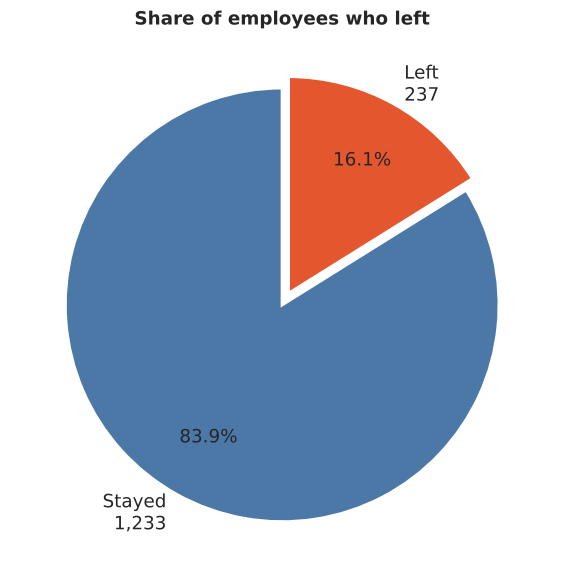

In [7]:
fig, ax = plt.subplots(figsize=(5.5,5.5))
counts = d.Attrition.value_counts()
ax.pie(counts, labels=[f'Stayed\n{counts["No"]:,}', f'Left\n{counts["Yes"]:,}'], colors=[PAL['No'],PAL['Yes']],
       autopct='%1.1f%%', startangle=90, explode=(0,0.06), wedgeprops={'edgecolor':'white','linewidth':2},
       textprops={'fontsize':12}, pctdistance=0.7)
ax.set_title('Share of employees who left')
plt.tight_layout(); plt.show()

**Interpretation:** About 84% of employees stayed and 16% (237 people) left. At roughly one in six, attrition is material for a manufacturer, but the split is also heavily imbalanced — a point to handle carefully in any predictive model (use recall/precision/AUC, not just accuracy).

#### Chart 2 — Bar chart: workforce by department

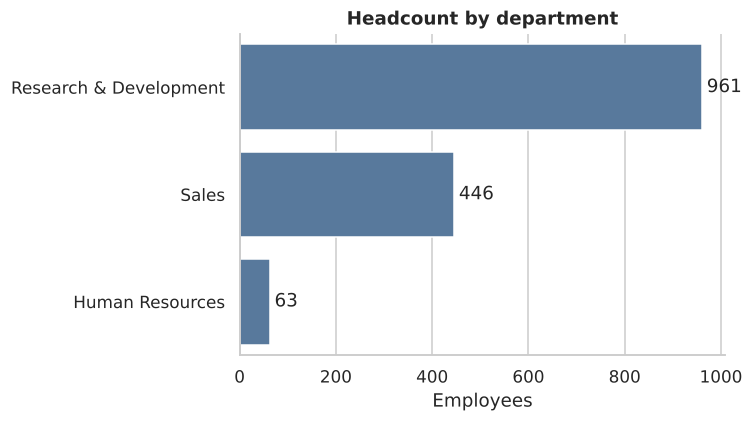

In [8]:
fig, ax = plt.subplots(figsize=(7,4))
order = d.Department.value_counts().index
sns.countplot(data=d, y='Department', order=order, color='#4C78A8', ax=ax)
for c in ax.containers: ax.bar_label(c, padding=3)
ax.set_title('Headcount by department'); ax.set_xlabel('Employees'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Interpretation:** Research & Development is the backbone of the company with 961 staff (65%), followed by Sales (446, 30%). HR is tiny at 63 people (4%). Because HR is so small, its attrition percentage is based on few people and swings easily.

In [9]:
print(d.Gender.value_counts(normalize=True).mul(100).round(1).to_dict())
print(d.MaritalStatus.value_counts(normalize=True).mul(100).round(1).to_dict())
print(d.BusinessTravel.value_counts(normalize=True).mul(100).round(1).to_dict())
print(d.OverTime.value_counts(normalize=True).mul(100).round(1).to_dict())
print(d[['Age','MonthlyIncome','YearsAtCompany','TotalWorkingYears','DistanceFromHome']].describe().round(1).loc[['mean','50%','min','max']])

{'Male': 60.0, 'Female': 40.0}
{'Married': 45.8, 'Single': 32.0, 'Divorced': 22.2}
{'Travel_Rarely': 71.0, 'Travel_Frequently': 18.8, 'Non-Travel': 10.2}
{'No': 71.7, 'Yes': 28.3}


       Age  MonthlyIncome  YearsAtCompany  TotalWorkingYears  DistanceFromHome
mean  36.9         6502.9             7.0               11.3               9.2
50%   36.0         4919.0             5.0               10.0               7.0
min   18.0         1009.0             0.0                0.0               1.0
max   60.0        19999.0            40.0               40.0              29.0


#### Chart 3 — Histogram: age distribution

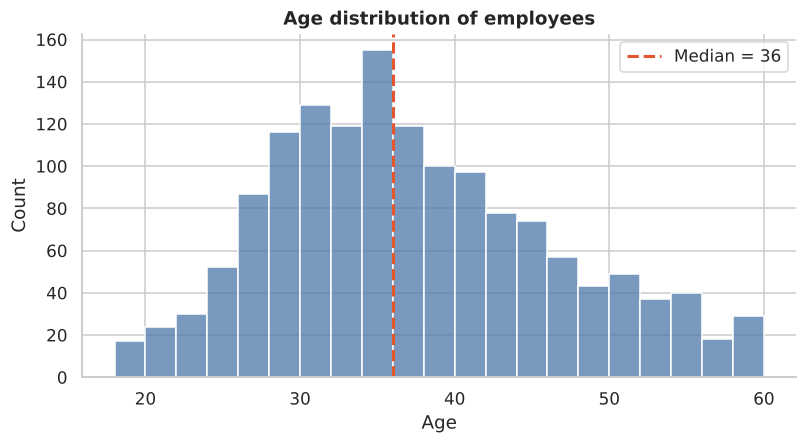

In [10]:
fig, ax = plt.subplots(figsize=(7.5,4.2))
sns.histplot(d.Age, bins=21, color='#4C78A8', edgecolor='white', ax=ax)
ax.axvline(d.Age.median(), color='#E4572E', ls='--', lw=2, label=f'Median = {d.Age.median():.0f}')
ax.set_title('Age distribution of employees'); ax.set_xlabel('Age'); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation:** The workforce is mid-career: ages run 18–60 with a median of 36 and most people between 30 and 43. The shape is roughly bell-shaped with a slight right tail, so there are fewer very young and very senior employees. This also means the youngest group (18–25) is small, so its attrition rate rests on ~100 people.

### Q2 — Which departments have the highest attrition?

#### Chart 4 — Bar chart: attrition rate by department

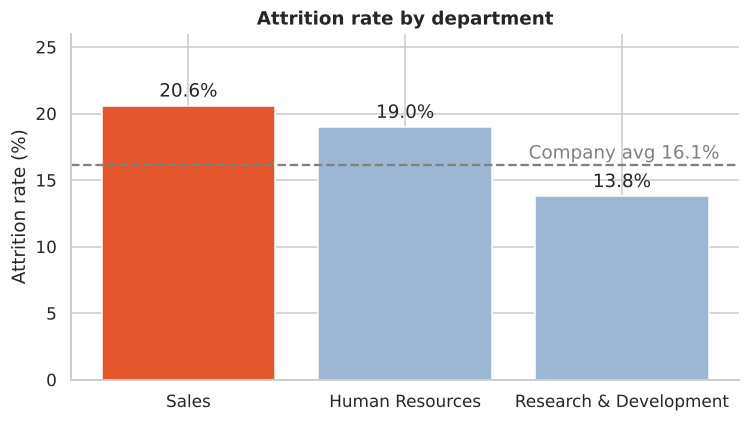

,Employees,Leavers
Department,,
Human Resources,63,12
Research & Development,961,133
Sales,446,92


In [11]:
r = rate('Department').sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(r.index, r.values, color=['#E4572E' if v==r.max() else '#9BB7D4' for v in r.values])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.axhline(d.Left.mean()*100, color='grey', ls='--', lw=1.5); ax.text(2.45, d.Left.mean()*100+0.5, 'Company avg 16.1%', ha='right', color='grey')
ax.set_ylabel('Attrition rate (%)'); ax.set_title('Attrition rate by department'); ax.set_ylim(0,26)
plt.tight_layout(); plt.show()
d.groupby('Department').Left.agg(['count','sum']).rename(columns={'count':'Employees','sum':'Leavers'})

**Interpretation:** Sales has the highest attrition at 20.6% (92 leavers), above the 16.1% company average. HR is next at 19.0%, but that is only 12 people out of 63, so treat it cautiously. R&D is lowest at 13.8%, yet because it is the biggest department it still contributes the most leavers in absolute terms (133). Sales is the department to prioritise.

### Q3 — Does age influence attrition?

#### Chart 5 — Boxplot: age by attrition status

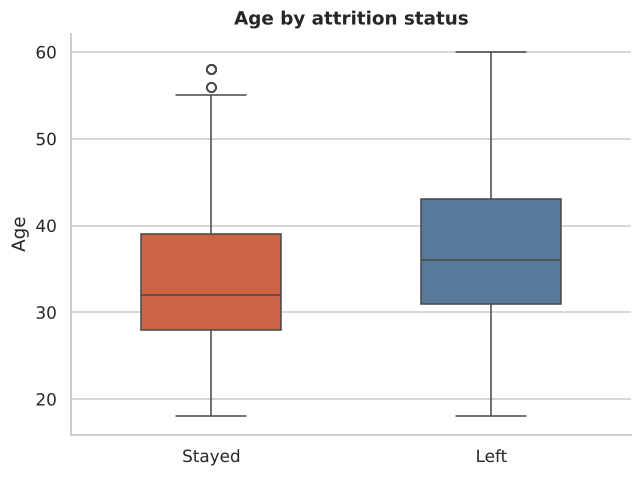

            count  mean  std   min   25%   50%   75%   max
Attrition                                                 
No         1233.0  37.6  8.9  18.0  31.0  36.0  43.0  60.0
Yes         237.0  33.6  9.7  18.0  28.0  32.0  39.0  58.0


In [12]:
fig, ax = plt.subplots(figsize=(6,4.5))
sns.boxplot(data=d, x='Attrition', y='Age', palette=PAL, ax=ax, width=0.5)
ax.set_title('Age by attrition status'); ax.set_xticklabels(['Stayed','Left']); ax.set_xlabel('')
plt.tight_layout(); plt.show()
print(d.groupby('Attrition').Age.describe().round(1))

**Interpretation:** Employees who left are clearly younger: median age 32 versus 36 for those who stayed, and the whole box sits lower (middle 50% roughly 28–39 vs 31–43). The distributions overlap a lot, so age alone does not decide who leaves, but it is a real signal.

#### Chart 6 — Bar chart: attrition rate by age band

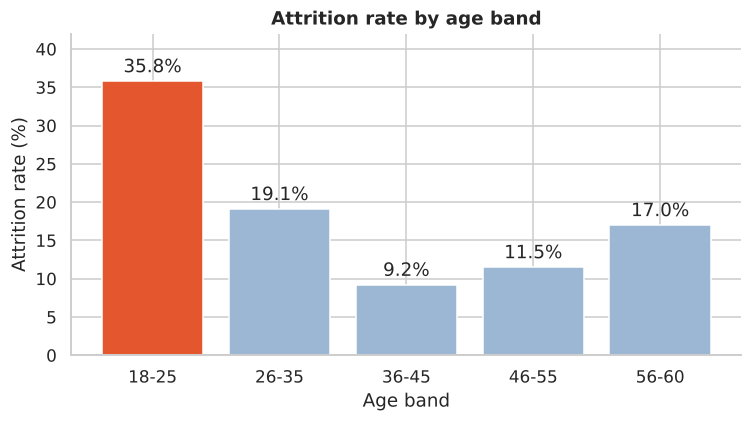

AgeBand
18-25    123
26-35    606
36-45    468
46-55    226
56-60     47
Name: count, dtype: int64

In [13]:
r = rate('AgeBand')
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(r.index.astype(str), r.values, color=['#E4572E' if v==r.max() else '#9BB7D4' for v in r.values])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_ylabel('Attrition rate (%)'); ax.set_xlabel('Age band'); ax.set_title('Attrition rate by age band'); ax.set_ylim(0,42)
plt.tight_layout(); plt.show()
d.AgeBand.value_counts().sort_index()

**Interpretation:** Age and attrition are inversely related until the late 50s. Employees aged 18–25 leave at 35.8% — more than double the company average — falling to 19.1% for 26–35 and just 9.2% for 36–45, the most stable group. There is a mild uptick for those 56+ (17.0%), likely retirement. **Yes, age matters: early-career staff are the flight risk.**

### Q4 — Does monthly income affect retention?

#### Chart 7 — Boxplot: monthly income by attrition status

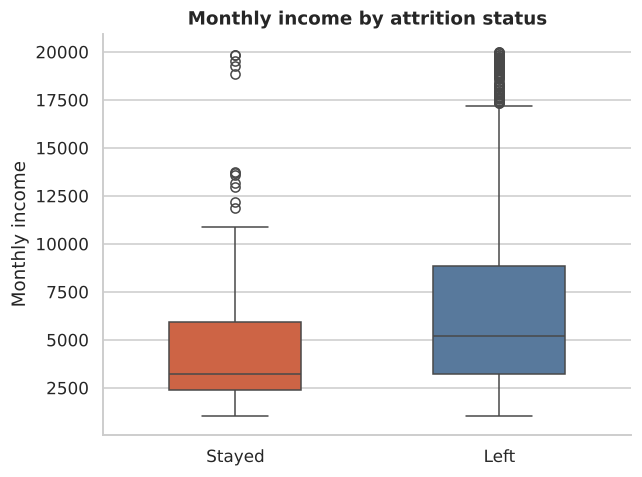

            count    mean     std     min     25%     50%     75%      max
Attrition                                                                 
No         1233.0  6833.0  4818.0  1051.0  3211.0  5204.0  8834.0  19999.0
Yes         237.0  4787.0  3640.0  1009.0  2373.0  3202.0  5916.0  19859.0


In [14]:
fig, ax = plt.subplots(figsize=(6,4.5))
sns.boxplot(data=d, x='Attrition', y='MonthlyIncome', palette=PAL, ax=ax, width=0.5)
ax.set_title('Monthly income by attrition status'); ax.set_xticklabels(['Stayed','Left']); ax.set_xlabel(''); ax.set_ylabel('Monthly income')
plt.tight_layout(); plt.show()
print(d.groupby('Attrition').MonthlyIncome.describe().round(0))

**Interpretation:** Leavers earn much less: median monthly income is 3,202 versus 5,204 for stayers (about 38% lower). Both groups have high-earner outliers, but almost no leavers are in the top of the pay range. Income is strongly right-skewed, so the median is a fairer summary than the mean.

#### Chart 8 — Histogram: income distribution by attrition

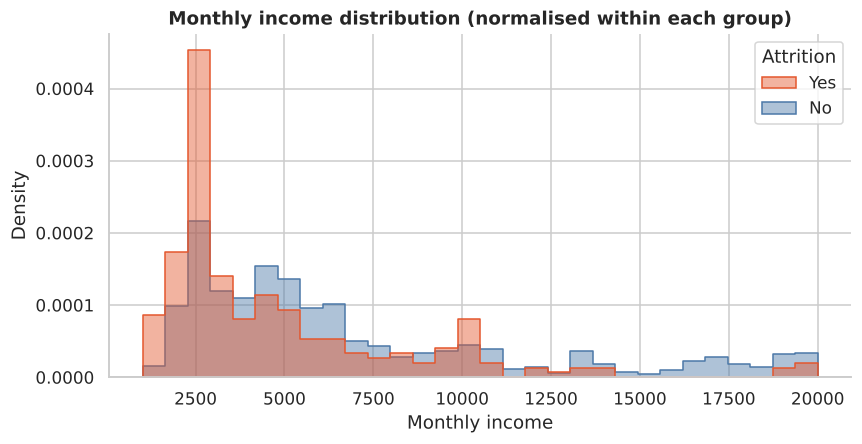

In [15]:
fig, ax = plt.subplots(figsize=(8,4.2))
sns.histplot(data=d, x='MonthlyIncome', hue='Attrition', palette=PAL, bins=30, stat='density', common_norm=False, element='step', alpha=.45, ax=ax)
ax.set_title('Monthly income distribution (normalised within each group)'); ax.set_xlabel('Monthly income')
plt.tight_layout(); plt.show()

**Interpretation:** Normalising each group to its own size makes the pattern visible: leavers are heavily concentrated at the low end (under ~5,000), while stayers have a long tail into higher pay. Retention improves as income rises.

In [16]:
r = rate('IncomeBand'); print(r)
print(rate('JobLevel'))

IncomeBand
Q1 (lowest)     29.3
Q2              14.2
Q3              10.6
Q4 (highest)    10.3
Name: Left, dtype: float64
JobLevel
1    26.3
2     9.7
3    14.7
4     4.7
5     7.2
Name: Left, dtype: float64


**Income quartiles confirm it** — see the table above: the lowest income quartile has the highest attrition and the top quartile the lowest, and attrition drops sharply with job level (26.3% at Level 1 vs 4.7–9.7% at Levels 2, 4 and 5). Pay, level and age are intertwined (younger staff are junior and paid less), so income is probably a *marker* of early-career status as well as a driver in its own right.

### Q5 — Does overtime influence attrition?

#### Chart 9 — Bar chart: attrition rate by overtime

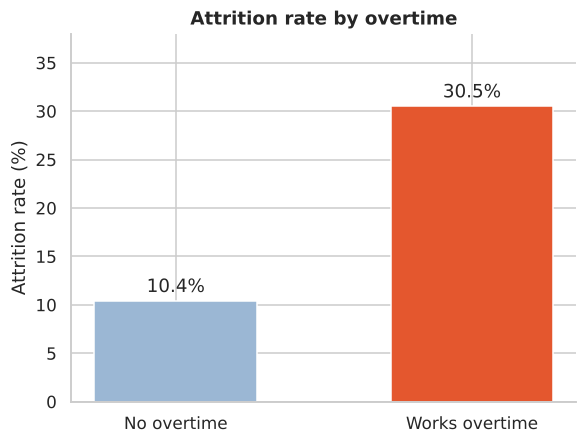

Attrition,No,Yes,All
OverTime,,,
No,944,110,1054
Yes,289,127,416
All,1233,237,1470


In [17]:
r = rate('OverTime')
fig, ax = plt.subplots(figsize=(5.5,4.2))
bars = ax.bar(['No overtime','Works overtime'], [r['No'], r['Yes']], color=['#9BB7D4','#E4572E'], width=.55)
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_ylabel('Attrition rate (%)'); ax.set_title('Attrition rate by overtime'); ax.set_ylim(0,38)
plt.tight_layout(); plt.show()
pd.crosstab(d.OverTime, d.Attrition, margins=True)

**Interpretation:** This is the strongest single pattern in the data. Employees who work overtime leave at 30.5% versus 10.4% for those who do not — roughly **three times higher**. Overtime workers are 28% of staff (416) but account for about 54% of all leavers (127 of 237). Workload and burnout look like a major driver and an actionable one.

### Q6 — Which job roles have the highest turnover?

#### Chart 10 — Bar chart: attrition rate by job role

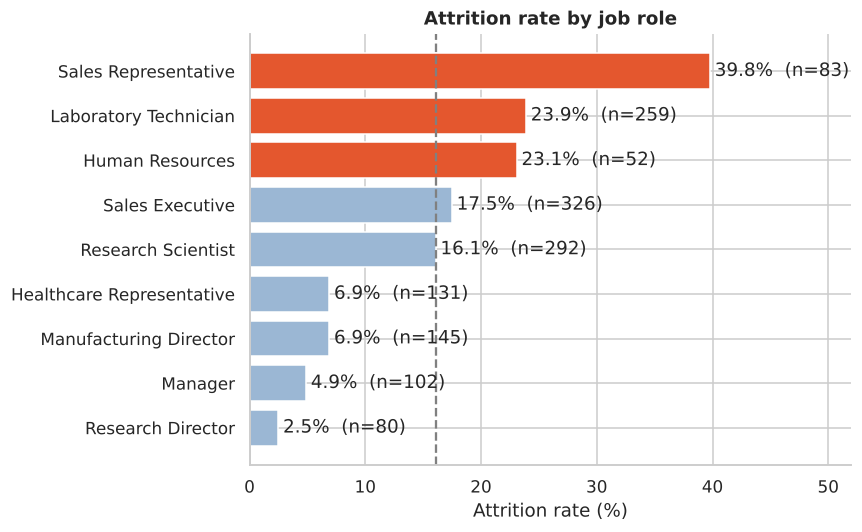

In [18]:
r = rate('JobRole').sort_values()
n = d.JobRole.value_counts()
fig, ax = plt.subplots(figsize=(8,5))
bars = ax.barh(r.index, r.values, color=['#E4572E' if v>=20 else '#9BB7D4' for v in r.values])
ax.bar_label(bars, labels=[f'{v:.1f}%  (n={n[k]})' for k,v in r.items()], padding=3)
ax.axvline(d.Left.mean()*100, color='grey', ls='--', lw=1.5)
ax.set_xlabel('Attrition rate (%)'); ax.set_title('Attrition rate by job role'); ax.set_xlim(0,52)
plt.tight_layout(); plt.show()

**Interpretation:** Sales Representatives have by far the highest turnover at 39.8% (33 of 83), more than twice the company average. Laboratory Technicians (23.9%) and HR staff (23.1%) follow. Senior and specialist roles — Research Directors (2.5%), Managers (4.9%), Healthcare Representatives and Manufacturing Directors (6.9% each) — are very stable. Turnover is concentrated in junior, front-line roles, consistent with the age and income findings.

### Q7 — Which variables look important for future modelling?

#### Chart 11 — Bar chart: correlation of numeric variables with attrition

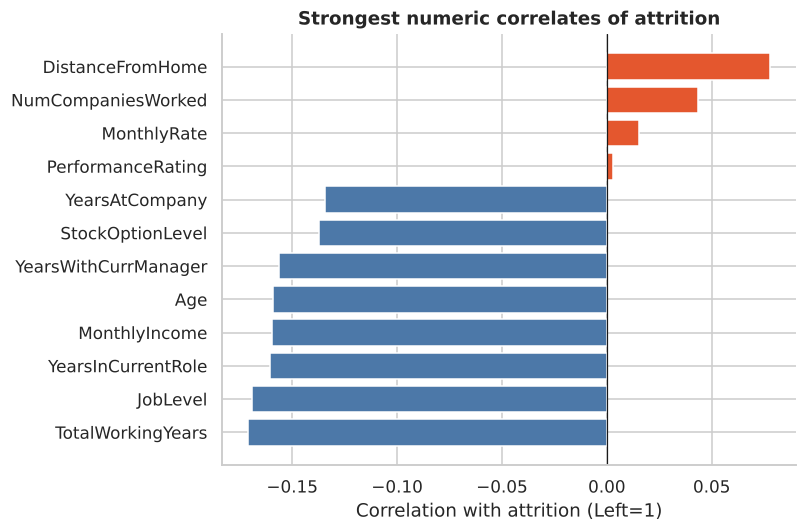

In [19]:
corr = d.select_dtypes('number').corr()['Left'].drop('Left').sort_values()
top = pd.concat([corr.head(8), corr.tail(4)])
fig, ax = plt.subplots(figsize=(7.5,5))
ax.barh(top.index, top.values, color=['#4C78A8' if v<0 else '#E4572E' for v in top.values])
ax.axvline(0,color='k',lw=.8); ax.set_xlabel('Correlation with attrition (Left=1)')
ax.set_title('Strongest numeric correlates of attrition')
plt.tight_layout(); plt.show()

**Interpretation:** Every numeric correlation is modest (|r| < 0.2), so no single numeric field predicts attrition alone. The strongest are *negative* — more total experience, higher job level, longer time in role, higher income, older age and longer tenure with the manager all go with staying. Distance from home is the main positive one. Categorical variables (especially OverTime, JobRole, MaritalStatus, BusinessTravel) add signal that correlation on numbers cannot show.

In [20]:
for c in ['MaritalStatus','BusinessTravel','StockOptionLevel','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance']:
    print(f'\n{c}\n', rate(c).to_string())


MaritalStatus
 MaritalStatus
Divorced    10.1
Married     12.5
Single      25.5

BusinessTravel
 BusinessTravel
Non-Travel            8.0
Travel_Frequently    24.9
Travel_Rarely        15.0

StockOptionLevel
 StockOptionLevel
0    24.4
1     9.4
2     7.6
3    17.6

JobSatisfaction
 JobSatisfaction
1    22.8
2    16.4
3    16.5
4    11.3

EnvironmentSatisfaction
 EnvironmentSatisfaction
1    25.4
2    15.0
3    13.7
4    13.5

WorkLifeBalance
 WorkLifeBalance
1    31.2
2    16.9
3    14.2
4    17.6


In [21]:
d['YearsGroup'] = pd.cut(d.YearsAtCompany,[-1,1,3,5,10,40],labels=['0-1','2-3','4-5','6-10','10+'])
print(rate('YearsGroup').to_string())
print(d.groupby('Attrition')[['DistanceFromHome','YearsSinceLastPromotion','NumCompaniesWorked']].mean().round(2))

YearsGroup
0-1     34.9
2-3     18.4
4-5     13.1
6-10    12.3
10+      8.1
           DistanceFromHome  YearsSinceLastPromotion  NumCompaniesWorked
Attrition                                                               
No                     8.92                     2.23                2.65
Yes                   10.63                     1.95                2.94


## 4. Initial business insights
### Five workforce observations
1. **Mid-career, R&D-heavy workforce.** Median age is 36; R&D employs 65% of staff, Sales 30%, HR 4%.
2. **Attrition is 16.1%** (237 of 1,470) — about one in six employees has left, and the data is imbalanced 84/16.
3. **Two-thirds male, mostly married.** 60% male, 46% married, 32% single, 22% divorced; gender shows only a small gap in attrition (male 17.0% vs female 14.8%).
4. **Pay is highly skewed.** Median monthly income is 4,919 but the mean is 6,503, pulled up by senior roles earning up to 19,999.
5. **A large minority works overtime and travels.** 28% do overtime and 29% travel (19% frequently), so workload is a real part of daily life for many.

### Five factors possibly contributing to attrition (with evidence)
| # | Factor | Evidence |
|---|---|---|
| 1 | **Overtime** | 30.5% attrition vs 10.4% without overtime; overtime staff are 28% of workforce but ~54% of leavers |
| 2 | **Young age / early career** | 35.8% attrition at 18–25 vs 9.2% at 36–45; median age of leavers 32 vs 36 |
| 3 | **Low income and junior level** | Median pay of leavers 3,202 vs 5,204; Job Level 1 attrition 26.3% |
| 4 | **Sales roles** | Sales Representatives 39.8%; Sales department 20.6% vs 13.8% for R&D |
| 5 | **Frequent travel & single status** | Frequent travellers 24.9% vs 8.0% non-travel; single staff 25.5% vs 10.1% divorced / 12.5% married |

Also notable: low stock-option level (24.4% at level 0 vs 7.6-9.4% at levels 1-2) and low job satisfaction (22.8% at score 1 vs 11.3% at 4).

> **Caution:** These are associations from one snapshot, not proof of cause. Overtime, age, pay and role overlap with each other; multivariate modelling is needed to separate their effects.

## 5. Variables to carry into predictive modelling
**Likely strongest:** OverTime, JobRole, MonthlyIncome, JobLevel, Age, TotalWorkingYears, YearsAtCompany / YearsInCurrentRole, StockOptionLevel, MaritalStatus, BusinessTravel, JobSatisfaction, EnvironmentSatisfaction.

**Likely weak / drop candidates:** HourlyRate, DailyRate, MonthlyRate, PerformanceRating, PercentSalaryHike, Education, EmployeeNumber (ID noise) and the constant columns EmployeeCount, StandardHours, Over18.

**Modelling notes:** one-hot encode categoricals; handle the 84/16 imbalance (stratified split, class weights, evaluate with recall/precision/F1/ROC-AUC); watch for multicollinearity between JobLevel, MonthlyIncome, TotalWorkingYears and Age; avoid using anything that would only be known *after* an employee leaves.

## Summary
Attrition at ABC Manufacturing is concentrated among **young, junior, lower-paid employees who work overtime**, especially in **Sales** roles. These are targeted, actionable groups: review overtime workload and compensation for early-career staff, and investigate why Sales Representatives leave at nearly 40%.